# EDA Dataset — Deteksi Jatuh Panti Jompo

Notebook ini berisi **analisis data eksploratif (EDA)** atas dataset yang dihasilkan pipeline preprocessing
(UR Fall cam0 + MCF). Proses pembuatannya (tahap, parameter, kode) ada di
[`preprocessing_pipeline.ipynb`](preprocessing_pipeline.ipynb); notebook ini hanya **membaca** data dan menjawab
pertanyaan tentang *isi* data.

**Sifat notebook:** read-only. Tidak ada gambar, label, atau skrip yang diubah. Bagian §4–§6 dan §8.5 membaca
gambar di `ml/data/processed_final/images` (tidak ikut di-commit), jadi notebook harus dijalankan di mesin yang
sudah menjalankan preprocessing. Pemindaian gambar memakan waktu sekitar 1–5 menit, tergantung cache disk.

**Dataset yang dianalisis**
- `processed_v2` (gabungan sebelum Tahap 5) lewat `frames_meta.csv`: dipakai untuk pertanyaan yang **mendasari**
  keputusan Tahap 5 (audit asli).
- `processed_final` (**dataset final** untuk training): dipakai untuk pemeriksaan kualitas dan distribusi akhir.

## Peta pertanyaan

| §  | Pertanyaan | Keputusan preprocessing yang dipengaruhi |
|----|------------|------------------------------------------|
| 2  | Panjang segmen anotasi MCF per aktivitas | stride dan guard band MCF (Tahap 2) |
| 3  | Jumlah gambar dan kelas di tiap tahap | — |
| 4  | Integritas file: gambar rusak, duplikat persis, format label | — |
| 5  | Kebocoran antar-split dan near-duplicate | split per video/skenario; stride vs hash |
| 6  | Resolusi gambar dan ukuran orang (termasuk orang terlalu kecil) | detektor `yolo11m` @960 untuk MCF |
| 7  | Review label | koreksi ADL (Tahap 5), `label_map.yaml` |
| 8  | Distribusi kelas dan sampel per kelas | subsampling transitional, `--mcf-split` |
| 9  | Durasi lying | aturan alarm 10 detik |
| 10 | Ringkasan temuan dan implikasinya | — |

Label sumber angka: **manifest** = dicatat skrip preprocessing; **dihitung** = dihitung di notebook ini dari
`frames_meta.csv` atau dari file gambar/label; **pembacaan visual** = pengamatan mata atas gambar kontak.

## 1. Persiapan

Jalur repo, gaya grafik, dan fungsi bantu. Warna kelas sama dengan notebook preprocessing:
biru = normal, oranye = transitional, aqua = lying. Setiap grafik disertai legenda dan tabel angka, karena warna
aqua kontrasnya rendah terhadap latar putih.

In [1]:
import sys, json, hashlib, importlib.util, warnings, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

sys.dont_write_bytecode = True   # jangan menulis __pycache__ ke repo

try:
    from IPython.display import display
except ImportError:              # dijalankan di luar Jupyter
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "ml" / "scripts").is_dir():
            return p
    raise FileNotFoundError("Jalankan notebook dari dalam repo (folder yang memuat ml/scripts).")


ROOT = find_root()
SCRIPTS = ROOT / "ml" / "scripts"
DATA = ROOT / "ml" / "data"
MCF_DIR = DATA / "mcf"
D_URFALL, D_MCF = DATA / "processed_urfall", DATA / "processed_mcf"
D_V2, D_FINAL = DATA / "processed_v2", DATA / "processed_final"

CLASS_NAMES = {0: "normal", 1: "transitional", 2: "lying_on_ground"}
CLASS_ORDER = list(CLASS_NAMES.values())
SPLITS = ("train", "val", "test")
SOURCES = ("urfall", "mcf")
SOURCE_LABEL = {"urfall": "UR Fall", "mcf": "MCF"}

# Tiga slot pertama palet kategorikal default (urutan tetap, tervalidasi untuk tiga seri).
CLASS_COLOR = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})


def load_script(name):
    """Muat ml/scripts/<name>.py sebagai modul tanpa menjalankan main()."""
    spec = importlib.util.spec_from_file_location(name, SCRIPTS / f"{name}.py")
    mod = importlib.util.module_from_spec(spec)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        spec.loader.exec_module(mod)
    return mod


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def rel(p):
    return Path(p).relative_to(ROOT).as_posix()


def pct(x):
    return np.round(100 * x, 1)


needed = [MCF_DIR / "annotations.csv", MCF_DIR / "label_map.yaml",
          D_URFALL / "dataset_manifest.json", D_MCF / "dataset_manifest.json", D_V2 / "dataset_manifest.json",
          D_V2 / "frames_meta.csv", D_FINAL / "dataset_manifest.json", D_FINAL / "data.yaml",
          *[D_FINAL / "images" / s for s in SPLITS], *[D_FINAL / "labels" / s for s in SPLITS]]
display(pd.DataFrame([{"berkas/folder": rel(p), "ada": "ya" if p.exists() else "TIDAK"} for p in needed]))

m1 = read_json(D_URFALL / "dataset_manifest.json")
mm = read_json(D_MCF / "dataset_manifest.json")
fin = read_json(D_FINAL / "dataset_manifest.json")
meta = pd.read_csv(D_V2 / "frames_meta.csv")
meta["kelas"] = meta.cls.map(CLASS_NAMES)

,berkas/folder,ada
0,ml/data/mcf/annotations.csv,ya
1,ml/data/mcf/label_map.yaml,ya
2,ml/data/processed_urfall/dataset_manifest.json,ya
3,ml/data/processed_mcf/dataset_manifest.json,ya
4,ml/data/processed_v2/dataset_manifest.json,ya
5,ml/data/processed_v2/frames_meta.csv,ya
6,ml/data/processed_final/dataset_manifest.json,ya
7,ml/data/processed_final/data.yaml,ya
8,ml/data/processed_final/images/train,ya
9,ml/data/processed_final/images/val,ya


## 2. EDA data mentah: panjang segmen anotasi MCF

Label MCF berupa **segmen waktu** di kamera acuan, bukan label per frame. Sebelum memilih stride dan guard band,
yang perlu diketahui adalah seberapa panjang tiap jenis segmen. Segmen yang pendek butuh stride rapat agar tetap
terwakili; segmen yang panjang dan statis bisa dijarangkan.

In [2]:
etm = load_script("extract_mcf_tables")
ann_df = pd.read_csv(MCF_DIR / "annotations.csv")
ann_df["panjang_frame"] = ann_df.end - ann_df.start + 1
seg = ann_df.groupby(["code", "code_name"]).panjang_frame.agg(segmen="count", median="median", min="min", max="max")
seg["skenario"] = ann_df.groupby(["code", "code_name"]).scenario.nunique()
print(f"{len(ann_df)} segmen dari {ann_df.scenario.nunique()} skenario (kamera acuan)")
display(seg)
print("Skenario tanpa segmen lying_on_ground (kode 3):",
      sorted(set(range(1, 25)) - set(ann_df.loc[ann_df.code == 3, "scenario"])))

163 segmen dari 24 skenario (kamera acuan)


,,segmen,median,min,max,skenario
code,code_name,,,,,
1,walking_standing_up,36,171.5,23,775,24
2,falling,25,38.0,19,128,23
3,lying_on_ground,23,121.0,30,177,22
4,crouching,11,42.0,16,247,4
5,moving_down,26,47.0,22,111,12
6,moving_up,29,50.0,24,220,13
7,sitting,9,89.0,49,186,9
8,lying_on_sofa,4,219.5,81,309,3


Skenario tanpa segmen lying_on_ground (kode 3): [23, 24]


**Interpretasi.** Segmen `falling` (kode 2) pendek: median 38 frame (±1,3 detik pada 30 FPS), sedangkan
`walking_standing_up` (kode 1) dan `lying_on_ground` (kode 3) jauh lebih panjang. Inilah alasan stride transitional
dibuat rapat (2) dan guard band tidak diterapkan pada transitional di Tahap 2 preprocessing.
S23 dan S24 tidak berisi lying, sehingga skenario test yang bisa menguji deteksi lying lebih sedikit dari jumlah
skenarionya (lihat §8.4). Kode 8 (sofa) hanya ada di 4 segmen (S13, S14, S23).

## 3. Jumlah gambar dan kelas

### 3.1 Alur jumlah frame dari data mentah sampai dataset final (manifest)

In [3]:
ur_saved = sum(m1["totals"].values())
mcf_cand = sum(v[1] for v in mm["retention_per_cam"].values())
mcf_saved = sum(v[0] for v in mm["retention_per_cam"].values())
n_final = sum(fin["counts"].values())
funnel = pd.DataFrame([
    ("UR Fall", "frame berlabel yang diperiksa", m1["frames_seen"]),
    ("UR Fall", "dilewati (tanpa label / label tak dikenal / tak terbaca)", -sum(m1["skipped"].values())),
    ("UR Fall", "dibuang stride", -sum(m1["dropped_by_stride"].values())),
    ("UR Fall", "dibuang: detektor tidak menemukan orang", -sum(m1["no_person_by_class"].values())),
    ("UR Fall", "tersimpan (processed)", ur_saved),
    ("MCF", "kandidat setelah stride + sinkronisasi 8 kamera", mcf_cand),
    ("MCF", "dibuang: di luar rentang video / video hilang",
     -(sum((mm["dropped_out_of_range"] or {}).values()) + len(mm["missing_videos"] or []))),
    ("MCF", "dibuang: detektor tidak menemukan orang", -sum(mm["dropped_no_detection"].values())),
    ("MCF", "tersimpan (processed_mcf)", mcf_saved),
    ("Gabungan", "processed_v2", len(meta)),
    ("Gabungan", "dibuang: subsampel transitional (hanya train)", -fin["dropped"]["transitional (disubsampel di train)"]),
    ("Gabungan", "dibuang: lying dari ADL yang ambigu", -fin["dropped"]["lying ADL dibuang"]),
    ("Gabungan", "DATASET FINAL processed_final", n_final),
], columns=["sumber", "langkah", "frame"])
display(funnel)
assert ur_saved + mcf_saved == len(meta) == n_final + sum(fin["dropped"].values())

,sumber,langkah,frame
0,UR Fall,frame berlabel yang diperiksa,11936
1,UR Fall,dilewati (tanpa label / label tak dikenal / ta...,0
2,UR Fall,dibuang stride,-7827
3,UR Fall,dibuang: detektor tidak menemukan orang,-1044
4,UR Fall,tersimpan (processed),3065
5,MCF,kandidat setelah stride + sinkronisasi 8 kamera,9723
6,MCF,dibuang: di luar rentang video / video hilang,0
7,MCF,dibuang: detektor tidak menemukan orang,-2846
8,MCF,tersimpan (processed_mcf),6877
9,Gabungan,processed_v2,9942


### 3.2 Kelas dan pasangan gambar–label di dataset final (dihitung dari file)

In [4]:
print((D_FINAL / "data.yaml").read_text(encoding="utf-8"))
rows = []
for s in SPLITS:
    imgs = {p.stem for p in (D_FINAL / "images" / s).glob("*.jpg")}
    lbls = {p.stem for p in (D_FINAL / "labels" / s).glob("*.txt")}
    other = [p.name for p in (D_FINAL / "images" / s).iterdir() if p.suffix.lower() != ".jpg"]
    rows.append({"split": s, "gambar .jpg": len(imgs), "label .txt": len(lbls),
                 "gambar tanpa label": len(imgs - lbls), "label tanpa gambar": len(lbls - imgs),
                 "file lain di folder gambar": len(other)})
pairs = pd.DataFrame(rows).set_index("split")
pairs.loc["total"] = pairs.sum()
display(pairs)

train: images/train
val: images/val
test: images/test
nc: 3
names:
  0: normal
  1: transitional
  2: lying_on_ground



,gambar .jpg,label .txt,gambar tanpa label,label tanpa gambar,file lain di folder gambar
split,,,,,
train,3768,3768,0,0,0
val,1476,1476,0,0,0
test,3401,3401,0,0,0
total,8645,8645,0,0,0


**Interpretasi.** Dataset final berisi **8.645 gambar dengan 3 kelas** (normal, transitional,
lying_on_ground). Setiap gambar punya tepat satu file label dan sebaliknya.
Dua penyebab frame hilang: **stride** (disengaja; 7.827 frame UR Fall) dan **detektor tidak menemukan orang**
(1.044 frame UR Fall dan 2.846 kandidat MCF). Kehilangan jenis kedua tidak netral, dan pengaruhnya dibahas di §7.4.
Catatan: angka MCF dihitung setelah stride, karena `prepare_mcf.py` tidak mencatat jumlah frame video mentah.

## 4. Integritas file: gambar rusak, duplikat persis, format label (baru)

Sejauh ini pemeriksaan "rusak" hanya terjadi **saat ekstraksi** (UR Fall `unreadable: 0`; penggabungan `skipped: {}`).
JPG final belum pernah dibuka ulang setelah ditulis. Sel berikut memindai **semua** gambar dan label final dalam
satu kali baca per file, lalu menyimpan hasilnya di tabel `files` yang dipakai §4–§6:

| Pemeriksaan | Cara | Kenapa |
|---|---|---|
| Gambar rusak | header JPEG (`FF D8`), penanda akhir (`FF D9`), dan decode penuh dengan OpenCV | file terpotong kadang masih bisa di-decode sebagian; penanda akhir menangkap kasus itu |
| Duplikat persis | MD5 isi file | dua file identik = sampel ganda |
| Format label | jumlah baris, jumlah kolom, kelas 0–2, koordinat 0–1, kotak keluar tepi | label rusak tidak selalu membuat training gagal, tetapi diam-diam merusak metrik |
| Hash untuk §5 | dHash 64-bit frame utuh dan potongan kotak orang | dipakai untuk near-duplicate |
| Ukuran untuk §6 | lebar × tinggi hasil decode | resolusi dan ukuran kotak dalam piksel |

In [5]:
def dhash64(gray):
    """dHash 64-bit: tanda selisih piksel bertetangga pada citra 9x8.

    Prinsipnya sama dengan compute_phash() di ml/scripts/dedup_check.py (yang walau bernama pHash sebenarnya
    menghitung dHash); di sini memakai INTER_AREA agar pengecilan tidak aliasing.
    """
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    return int.from_bytes(np.packbits(small[:, 1:] > small[:, :-1]).tobytes(), "big")


def scan_split(split):
    rows = []
    for lf in sorted((D_FINAL / "labels" / split).glob("*.txt")):
        ip = D_FINAL / "images" / split / f"{lf.stem}.jpg"
        raw = ip.read_bytes() if ip.exists() else b""
        img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE) if raw else None
        lines = [l.split() for l in lf.read_text().splitlines() if l.strip()]
        r = {"stem": lf.stem, "split": split, "src": "mcf" if lf.stem.startswith("mcf_") else "urfall",
             "bytes": len(raw), "jpeg_header": raw[:2] == b"\xff\xd8", "jpeg_eoi": raw[-2:] == b"\xff\xd9",
             "md5": hashlib.md5(raw).hexdigest(), "decoded": img is not None,
             "n_obj": len(lines), "n_cols": len(lines[0]) if lines else 0}
        if lines and len(lines[0]) == 5:
            r.update(cls=int(lines[0][0]), **dict(zip(("xc", "yc", "w", "h"), map(float, lines[0][1:]))))
        if img is not None:
            H, W = img.shape
            r.update(W=W, H=H, hash_full=dhash64(img))
            if "xc" in r:
                x0 = max(int(round((r["xc"] - r["w"] / 2) * W)), 0)
                x1 = min(int(round((r["xc"] + r["w"] / 2) * W)), W)
                y0 = max(int(round((r["yc"] - r["h"] / 2) * H)), 0)
                y1 = min(int(round((r["yc"] + r["h"] / 2) * H)), H)
                if x1 > x0 and y1 > y0:
                    r["hash_crop"] = dhash64(img[y0:y1, x0:x1])
        rows.append(r)
    return rows


t0 = time.time()
files = pd.DataFrame([r for s in SPLITS for r in scan_split(s)])
print(f"{len(files)} pasangan gambar-label dipindai dalam {time.time() - t0:.0f} detik")

8645 pasangan gambar-label dipindai dalam 36 detik


### 4.1 Gambar rusak

In [6]:
bad = pd.DataFrame({
    "file gambar hilang": files.bytes == 0,
    "header bukan JPEG": ~files.jpeg_header,
    "terpotong (tanpa penanda akhir FF D9)": ~files.jpeg_eoi,
    "gagal di-decode": ~files.decoded,
}).groupby(files.split).sum().reindex(list(SPLITS))
bad.loc["total"] = bad.sum()
display(bad)
kb = files.groupby("src").bytes.agg(n="count", min="min", p1=lambda s: s.quantile(.01), median="median", max="max")
kb[["min", "p1", "median", "max"]] = (kb[["min", "p1", "median", "max"]] / 1024).round(1)
print("Ukuran file (KB) per sumber:")
display(kb)

,file gambar hilang,header bukan JPEG,terpotong (tanpa penanda akhir FF D9),gagal di-decode
split,,,,
train,0,0,0,0
val,0,0,0,0
test,0,0,0,0
total,0,0,0,0


Ukuran file (KB) per sumber:


,n,min,p1,median,max
src,,,,,
mcf,6077,77.8,88.6,113.7,131.0
urfall,2568,43.0,44.8,73.4,110.4


**Interpretasi.** Tidak ada gambar hilang, header salah, terpotong, atau gagal di-decode. File terkecil sekitar
43 KB, jauh dari ukuran yang mencurigakan untuk JPEG 640×480/720×480 berkualitas 95. Dataset final bebas file rusak.

### 4.2 Duplikat persis (MD5)

In [7]:
dup = files.groupby("md5").stem.agg(list)
dup = dup[dup.str.len() > 1]
print(f"Grup file identik byte-per-byte: {len(dup)}")
if len(dup):
    display(dup.to_frame("file"))

Grup file identik byte-per-byte: 0


**Interpretasi.** Tidak ada dua file yang identik byte-per-byte. Ini wajar karena setiap frame diambil dari
nomor frame berbeda. Kemiripan visual (near-duplicate) adalah pertanyaan lain yang dibahas di §5.

### 4.3 Format label

In [8]:
lab = files.dropna(subset=["cls"])
edge = 1e-6
checks = {
    "file label": len(files),
    "jumlah objek per label": dict(Counter(files.n_obj)),
    "jumlah kolom per baris": dict(Counter(files.n_cols)),
    "kelas di luar 0..2": int((~lab.cls.isin([0, 1, 2])).sum()),
    "koordinat di luar 0..1": int((lab[["xc", "yc", "w", "h"]].lt(0) | lab[["xc", "yc", "w", "h"]].gt(1)).any(axis=1).sum()),
    "kotak lebar/tinggi nol": int(((lab.w <= 0) | (lab.h <= 0)).sum()),
    "kotak keluar tepi gambar": int(((lab.xc - lab.w / 2 < -edge) | (lab.xc + lab.w / 2 > 1 + edge) |
                                     (lab.yc - lab.h / 2 < -edge) | (lab.yc + lab.h / 2 > 1 + edge)).sum()),
}
for k, v in checks.items():
    print(f"  {k:<26}: {v}")

  file label                : 8645
  jumlah objek per label    : {1: 8645}
  jumlah kolom per baris    : {5: 8645}
  kelas di luar 0..2        : 0
  koordinat di luar 0..1    : 0
  kotak lebar/tinggi nol    : 0
  kotak keluar tepi gambar  : 0


**Interpretasi.** Setiap label berisi **tepat satu objek** dengan format YOLO 5 kolom yang valid. Satu objek
per gambar adalah konsekuensi desain (detektor hanya mengambil satu kotak orang). Kedua dataset sumber memang
merekam satu aktor, jadi ini sesuai; tetapi model **tidak pernah melihat contoh dengan lebih dari satu orang**,
padahal di panti jompo pengasuh atau penghuni lain bisa ada di frame yang sama.

## 5. Kebocoran antar-split dan near-duplicate

### 5.1 Kebocoran: satu video/skenario di lebih dari satu split (audit #5)

In [9]:
leak_v2 = int((meta.groupby(["group", "video"]).split.nunique() > 1).sum())
fm = files.join(meta.set_index("stem")[["group", "video", "cam", "frame"]], on="stem")
assert fm.group.notna().all(), "ada file final yang tidak ada di frames_meta.csv"
leak_final = int((fm.groupby(["group", "video"]).split.nunique() > 1).sum())
print(f"processed_v2     : video/skenario di >1 split = {leak_v2}")
print(f"dataset final    : video/skenario di >1 split = {leak_final}")
print(f"nama file unik lintas split: {fm.stem.is_unique}")

processed_v2     : video/skenario di >1 split = 0
dataset final    : video/skenario di >1 split = 0
nama file unik lintas split: True


**Interpretasi.** Tidak ada kebocoran tingkat video/skenario. Catatan: semua 24 skenario MCF direkam di
**ruangan yang sama dengan 8 kamera yang sama**, jadi split per skenario mencegah kebocoran *kejadian*, tetapi
tidak mencegah kesamaan *latar belakang* antara train dan test. Efeknya terlihat di §5.3.

### 5.2 Metode near-duplicate

Duplikat persis (§4.2) tidak ada, tetapi frame bisa **hampir sama**. Hash 64-bit (dHash) dihitung dua kali:

- **frame utuh**: mengukur kemiripan seluruh gambar, termasuk latar belakang;
- **potongan kotak orang**: mengukur kemiripan *pose dan penampilan orang*, yang sebenarnya dipelajari model.

Untuk setiap gambar dicari tetangga terdekat (jarak Hamming terkecil, 0–64) dalam tiga kelompok: **video sama**,
**split sama tetapi video lain**, dan **split lain**. Ambang ≤ 6 dan ≤ 10 mengikuti pipeline awal (lying ≤ 6,
normal ≤ 10).

*Keterbatasan:* dHash memperkecil gambar menjadi 9×8 piksel, jadi kasar. Potongan orang yang kecil menjadi sangat
kabur; jarak kecil di sana berarti "mirip secara garis besar", bukan identik.

In [10]:
h_full = fm.hash_full.astype("uint64").to_numpy()
h_crop = fm.hash_crop.astype("uint64").to_numpy()
split_id = pd.factorize(fm.split)[0]
video_id = pd.factorize(fm.group + "/" + fm.video)[0]
RELATIONS = ("video sama", "split sama, video lain", "split lain")


def nearest(h, chunk=512):
    """Jarak Hamming ke tetangga terdekat per relasi, plus indeks tetangga terdekat di split lain."""
    n = len(h)
    out = {k: np.empty(n, np.int16) for k in RELATIONS}
    arg_other = np.empty(n, np.int64)
    for i in range(0, n, chunk):
        j = min(i + chunk, n)
        d = np.bitwise_count(h[i:j, None] ^ h[None, :]).astype(np.int16)
        d[np.arange(j - i), np.arange(i, j)] = 99            # abaikan diri sendiri
        same_split = split_id[i:j, None] == split_id[None, :]
        same_video = video_id[i:j, None] == video_id[None, :]
        for k, m in zip(RELATIONS, (same_video, same_split & ~same_video, ~same_split)):
            dm = np.where(m, d, 99)
            out[k][i:j] = dm.min(1)
            if k == "split lain":
                arg_other[i:j] = dm.argmin(1)
    return out, arg_other


def summarize(nn):
    rows = []
    for k in RELATIONS:
        for (s, so), idx in fm.groupby(["split", "src"]).indices.items():
            x = nn[k][idx]
            rows.append({"relasi": k, "split": s, "sumber": so, "n": len(x), "d=0 (%)": pct((x == 0).mean()),
                         "d≤6 (%)": pct((x <= 6).mean()), "d≤10 (%)": pct((x <= 10).mean()),
                         "median d": float(np.median(x))})
    t = pd.DataFrame(rows)
    t["relasi"] = pd.Categorical(t.relasi, RELATIONS)
    t["split"] = pd.Categorical(t.split, SPLITS)
    return t.sort_values(["relasi", "split", "sumber"]).set_index(["relasi", "split", "sumber"])


nn_full, arg_full = nearest(h_full)
nn_crop, arg_crop = nearest(h_crop)
print("=== Frame utuh: persen gambar yang punya tetangga sedekat d ===")
display(summarize(nn_full))

=== Frame utuh: persen gambar yang punya tetangga sedekat d ===


n  d=0 (%)  d≤6 (%)  d≤10 (%)  \
relasi                 split sumber                                     
video sama             train mcf     2122     62.4     98.5      99.9   
                             urfall  1646     51.1     99.9     100.0   
                       val   mcf     1078     69.4     99.0     100.0   
                             urfall   398     74.6    100.0     100.0   
                       test  mcf     2877     70.8     99.7     100.0   
                             urfall   524     73.5     99.8     100.0   
split sama, video lain train mcf     2122     29.1     99.5     100.0   
                             urfall  1646     31.1     98.2      99.8   
                       val   mcf     1078     26.6     91.0      99.8   
                             urfall   398      8.3     80.4      81.9   
                       test  mcf     2877     15.4     67.2      79.4   
                             urfall   524     20.2     63.0      69.5   
split lain             train mcf     2122      0.0     78.3      99.5   
                             urfall  1646      1.1     17.9      18.5   
                       val   mcf     1078      0.4     89.3      99.8   
                             urfall   398     17.6     98.5     100.0   
                       test  mcf     2877      0.1     64.1      97.1   
                             urfall   524     11.1     79.0      84.0   

                                     median d  
relasi                 split sumber            
video sama             train mcf          0.0  
                             urfall       0.0  
                       val   mcf          0.0  
                             urfall       0.0  
                       test  mcf          0.0  
                             urfall       0.0  
split sama, video lain train mcf          1.0  
                             urfall       1.0  
                       val   mcf          1.0  
                             urfall       3.0  
                       test  mcf          3.0  
                             urfall       2.0  
split lain             train mcf          5.0  
                             urfall      16.0  
                       val   mcf          3.0  
                             urfall       2.0  
                       test  mcf          5.0  
                             urfall       3.0

In [11]:
src_a, cam_a = fm.src.to_numpy(str), fm.cam.fillna(0).astype(int).to_numpy()
close = nn_full["split lain"] <= 6
partner = arg_full[close]
print(f"Gambar dengan tetangga frame-utuh d≤6 di split lain: {close.sum()} dari {len(fm)}")
print(f"  pasangannya dari sumber yang sama: {pct((src_a[close] == src_a[partner]).mean())}%")
mcf_close = close & (src_a == "mcf")
print(f"  MCF: pasangannya dari kamera yang sama: {pct((cam_a[mcf_close] == cam_a[arg_full[mcf_close]]).mean())}%")

Gambar dengan tetangga frame-utuh d≤6 di split lain: 5569 dari 8645
  pasangannya dari sumber yang sama: 100.0%
  MCF: pasangannya dari kamera yang sama: 100.0%


### 5.3 Interpretasi frame utuh

Hash frame utuh **tidak bisa dipakai sebagai detektor duplikat** di dataset ini:

- Mayoritas gambar punya tetangga dengan hash **identik** (d = 0) di video yang sama, padahal frame-nya berbeda
  nomor dan posenya bisa berbeda. Orang hanya menempati sebagian kecil gambar; hash 9×8 didominasi latar belakang
  yang diam.
- Sebagian besar gambar MCF punya tetangga d ≤ 6 **di split lain** (train 78%, val 89%, test 64%), dan **seluruh**
  pasangan itu berasal dari **kamera yang sama** pada skenario lain. Ini bukan kebocoran kejadian; ini bukti bahwa
  **train dan test MCF berbagi ruangan dan sudut kamera yang sama**. Hal serupa terjadi pada UR Fall val/test
  (98% dan 79% punya tetangga d ≤ 6 di split lain), sehingga ruangan UR Fall di val/test juga sudah muncul di split
  lain.

Implikasi: hasil test MCF mengukur generalisasi ke **kejadian dan aktor baru di ruangan yang sudah dikenal**, bukan
ke ruangan baru seperti panti jompo sungguhan. Ini juga mendukung (belakangan) pilihan preprocessing memakai stride,
bukan dedup hash frame utuh: dedup seperti itu akan menganggap hampir semua frame satu kamera sebagai duplikat.

In [12]:
print("=== Potongan kotak orang: persen gambar yang punya tetangga sedekat d ===")
display(summarize(nn_crop))

tr = np.where(fm.split.to_numpy(str) == "train")[0]
d_tr = np.vstack([np.bitwise_count(h_crop[tr[i:i + 512], None] ^ h_crop[None, tr]).astype(np.int8)
                  for i in range(0, len(tr), 512)])
d_full_tr = np.vstack([np.bitwise_count(h_full[tr[i:i + 512], None] ^ h_full[None, tr]).astype(np.int8)
                       for i in range(0, len(tr), 512)])
rows = []
for thr in (0, 6, 10):
    row = {"ambang d": thr}
    for name, d in (("frame utuh", d_full_tr), ("potongan orang", d_tr)):
        r_, c_ = np.nonzero(d <= thr)
        n_comp, _ = connected_components(coo_matrix((np.ones(len(r_)), (r_, c_)), shape=d.shape), directed=False)
        row[f"kelompok ({name})"] = n_comp
        row[f"frame 'unik' ({name}, %)"] = pct(n_comp / len(tr))
    rows.append(row)
print(f"Train: {len(tr)} gambar dikelompokkan bila saling terhubung lewat pasangan berjarak ≤ ambang")
display(pd.DataFrame(rows).set_index("ambang d"))

=== Potongan kotak orang: persen gambar yang punya tetangga sedekat d ===


n  d=0 (%)  d≤6 (%)  d≤10 (%)  \
relasi                 split sumber                                     
video sama             train mcf     2122      4.1     29.4      40.4   
                             urfall  1646      3.2     35.1      61.4   
                       val   mcf     1078      2.6     27.2      46.5   
                             urfall   398      3.0     59.8      87.9   
                       test  mcf     2877      2.6     32.4      46.8   
                             urfall   524      3.2     55.2      80.9   
split sama, video lain train mcf     2122      0.0      1.4       7.4   
                             urfall  1646      0.0     10.4      31.5   
                       val   mcf     1078      0.0      0.7       5.8   
                             urfall   398      0.0      0.5       4.8   
                       test  mcf     2877      0.0      0.7       3.9   
                             urfall   524      0.0      9.0      31.1   
split lain             train mcf     2122      0.0      0.1       6.4   
                             urfall  1646      0.0      0.4       8.7   
                       val   mcf     1078      0.0      0.1       6.2   
                             urfall   398      0.0      3.8      23.9   
                       test  mcf     2877      0.0      0.1       6.9   
                             urfall   524      0.0      2.7      17.7   

                                     median d  
relasi                 split sumber            
video sama             train mcf         13.0  
                             urfall       9.0  
                       val   mcf         11.0  
                             urfall       5.0  
                       test  mcf         11.0  
                             urfall       6.0  
split sama, video lain train mcf         14.0  
                             urfall      13.0  
                       val   mcf         15.0  
                             urfall      14.0  
                       test  mcf         15.0  
                             urfall      12.0  
split lain             train mcf         14.0  
                             urfall      15.0  
                       val   mcf         13.0  
                             urfall      13.0  
                       test  mcf         14.0  
                             urfall      13.0

Train: 3768 gambar dikelompokkan bila saling terhubung lewat pasangan berjarak ≤ ambang


,kelompok (frame utuh),"frame 'unik' (frame utuh, %)",kelompok (potongan orang),"frame 'unik' (potongan orang, %)"
ambang d,,,,
0,1873,49.7,3682,97.7
6,16,0.4,2788,74.0
10,12,0.3,2038,54.1


### 5.4 Interpretasi potongan orang

Pada level potongan orang, gambarannya berbeda dan lebih bermakna:

- **Lintas split**, hanya 0,1–3,8% gambar yang punya tetangga d ≤ 6 (median jarak 13–15). Pose orang di val/test
  praktis tidak "disalin" dari split lain.
- **Di dalam train**, sekitar seperempat gambar bergabung ke kelompok yang sama pada d ≤ 6. Artinya, dari 3.768
  gambar train, jumlah "pose yang berbeda secara garis besar" kira-kira 2.800, dan turun ke sekitar 2.000 pada d ≤ 10.
  Sumbernya terutama frame berdekatan dari video yang sama.

Tidak ada frame yang dihapus berdasarkan analisis ini. Menghapus frame mengubah dataset dan butuh keputusan
tersendiri. Angka ini dipakai untuk menakar seberapa besar sampel efektif, misalnya saat menilai risiko overfit
model yang lebih besar.

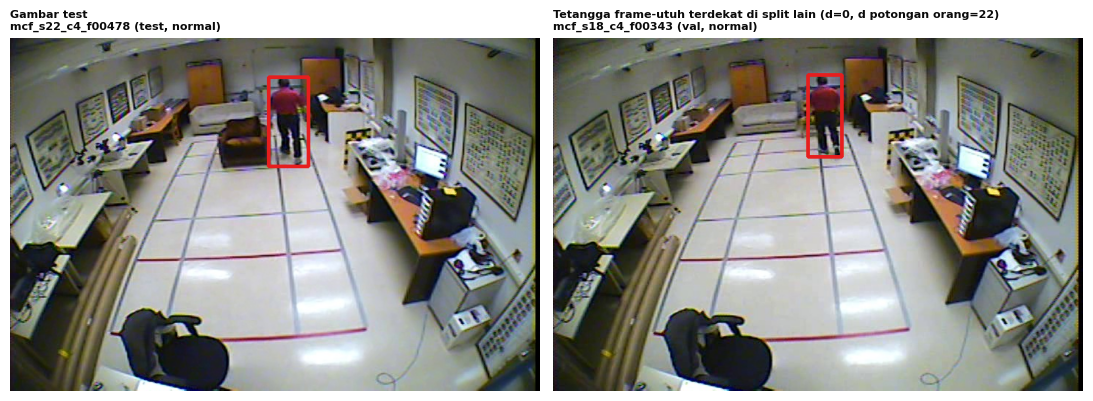

In [13]:
def draw(ax, i, title):
    r = fm.iloc[i]
    img = cv2.cvtColor(cv2.imread(str(D_FINAL / "images" / r.split / f"{r.stem}.jpg")), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    x0, y0 = int((r.xc - r.w / 2) * W), int((r.yc - r.h / 2) * H)
    cv2.rectangle(img, (x0, y0), (int(x0 + r.w * W), int(y0 + r.h * H)), (230, 30, 30), 3)
    ax.imshow(img)
    ax.set_title(f"{title}\n{r.stem} ({r.split}, {CLASS_NAMES[int(r.cls)]})", fontsize=8, loc="left")
    ax.axis("off")


test_mcf = np.where((fm.split.to_numpy(str) == "test") & (src_a == "mcf") & (nn_full["split lain"] == 0))[0]
i = test_mcf[len(test_mcf) // 2] if len(test_mcf) else int(np.argmin(np.where(src_a == "mcf", nn_full["split lain"], 99)))
j = arg_full[i]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
draw(axes[0], i, "Gambar test")
draw(axes[1], j, f"Tetangga frame-utuh terdekat di split lain (d={nn_full['split lain'][i]}, "
                 f"d potongan orang={int(np.bitwise_count(h_crop[i] ^ h_crop[j]))})")
plt.tight_layout()
plt.show()

Contoh di atas memperlihatkan kenapa hash frame utuh menyesatkan: dua gambar dari skenario dan split berbeda
memiliki hash frame utuh yang sama, karena ruangan dan kameranya sama, sedangkan jarak potongan orangnya jauh.

## 6. Resolusi gambar dan ukuran orang

### 6.1 Resolusi gambar (baru)

In [14]:
res = fm.groupby(["src", "W", "H"]).size().rename("gambar").reset_index()
res["skala ke imgsz 640 (sisi terpanjang)"] = (640 / res[["W", "H"]].max(axis=1)).round(3)
display(res)
display(fm.pivot_table(index="src", columns="split", values="stem", aggfunc="count").reindex(columns=list(SPLITS)))

,src,W,H,gambar,skala ke imgsz 640 (sisi terpanjang)
0,mcf,720,480,6077,0.889
1,urfall,640,480,2568,1.000


split,train,val,test
src,,,
mcf,2122,1078,2877
urfall,1646,398,524


**Interpretasi.** Hanya ada dua resolusi: **UR Fall 640×480** (rasio 4:3) dan **MCF 720×480** (rasio 3:2).
Tidak ada gambar beresolusi rendah. Saat training dengan `imgsz=640`, gambar MCF dikecilkan ke 0,889× (orang ikut
mengecil sekitar 11%) dan diberi padding atas-bawah; UR Fall tidak diskalakan. Menaikkan `imgsz` di atas 640 tidak
menambah detail untuk UR Fall (resolusi aslinya 640) dan hanya menambah sedikit untuk MCF (asli 720), konsisten
dengan catatan EXP-008.

### 6.2 Ukuran kotak orang dalam piksel (baru) dan "orang terlalu kecil"

Kategori ukuran mengikuti konvensi COCO: **small** luas < 32² piksel, **medium** < 96², **large** ≥ 96². Detektor
umumnya jauh lebih lemah pada objek small. Dihitung dua kali: pada resolusi asli, dan setelah gambar diskalakan ke
`imgsz 640` seperti saat training.

In [15]:
fm["bw"], fm["bh"] = fm.w * fm.W, fm.h * fm.H
fm["area"] = fm.bw * fm.bh
fm["area_640"] = fm.area * (640 / fm[["W", "H"]].max(axis=1)) ** 2
bins, labels = [0, 32 ** 2, 96 ** 2, np.inf], ["small", "medium", "large"]
fm["ukuran"] = pd.cut(fm.area, bins, labels=labels, right=False)
fm["ukuran_640"] = pd.cut(fm.area_640, bins, labels=labels, right=False)
fm["kelas"] = fm.cls.astype(int).map(CLASS_NAMES)

for col, judul in (("ukuran", "resolusi asli"), ("ukuran_640", "setelah diskalakan ke 640")):
    t = pd.crosstab([fm.kelas, fm.src], fm[col]).reindex(CLASS_ORDER, level=0)
    t["medium (%)"] = pct(t["medium"] / t.sum(axis=1))
    print(f"Kategori ukuran COCO, {judul}:")
    display(t)

print("Lebar dan tinggi kotak (piksel, resolusi asli):")
desc = fm.groupby(["kelas", "src"])[["bw", "bh"]].quantile([0, .05, .5]).unstack().round(0)
desc.columns = [f"{'lebar' if a == 'bw' else 'tinggi'} {'min' if q == 0 else ('p5' if q == .05 else 'median')}"
                for a, q in desc.columns]
display(desc.reindex(CLASS_ORDER, level=0))

Kategori ukuran COCO, resolusi asli:


ukuran                  small  medium  large  medium (%)
kelas           src                                     
normal          mcf         0     817   1830        30.9
                urfall      0      16   1394         1.1
transitional    mcf         0     496   1949        20.3
                urfall      0       3    946         0.3
lying_on_ground mcf         1     188    796        19.1
                urfall      0       1    208         0.5

Kategori ukuran COCO, setelah diskalakan ke 640:


ukuran_640              small  medium  large  medium (%)
kelas           src                                     
normal          mcf         2    1129   1516        42.7
                urfall      0      16   1394         1.1
transitional    mcf         0     766   1679        31.3
                urfall      0       3    946         0.3
lying_on_ground mcf         5     266    714        27.0
                urfall      0       1    208         0.5

Lebar dan tinggi kotak (piksel, resolusi asli):


lebar min  lebar p5  lebar median  tinggi min  \
kelas           src                                                     
normal          mcf          18.0      46.0          88.0        35.0   
                urfall       37.0      70.0         111.0        76.0   
transitional    mcf          31.0      54.0         106.0        42.0   
                urfall       55.0      89.0         146.0        60.0   
lying_on_ground mcf          13.0      57.0         147.0        37.0   
                urfall       67.0     122.0         263.0        22.0   

                        tinggi p5  tinggi median  
kelas           src                               
normal          mcf          77.0          147.0  
                urfall      154.0          264.0  
transitional    mcf          77.0          138.0  
                urfall      133.0          214.0  
lying_on_ground mcf          60.0          110.0  
                urfall       79.0          141.0

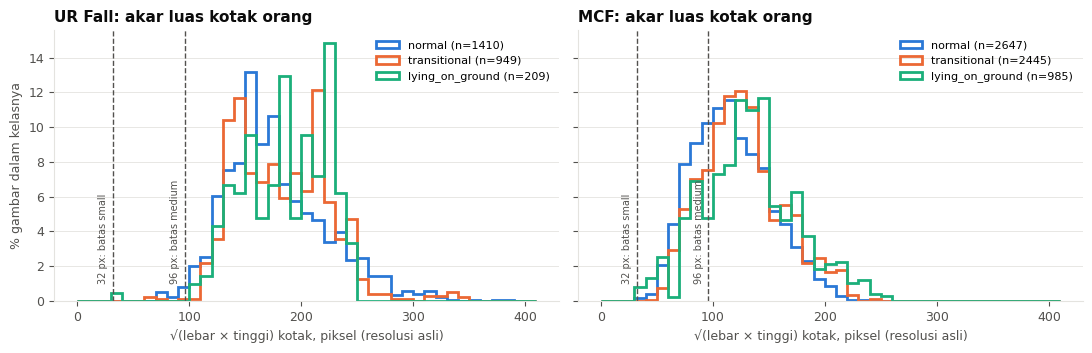

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
edges = np.arange(0, 420, 10)
for ax, so in zip(axes, SOURCES):
    for k, nm in CLASS_NAMES.items():
        v = np.sqrt(fm.loc[(fm.src == so) & (fm.cls == k), "area"])
        ax.hist(v, bins=edges, weights=np.full(len(v), 100 / len(v)), histtype="step", lw=2,
                color=CLASS_COLOR[k], label=f"{nm} (n={len(v)})")
    for x, t in ((32, "32 px: batas small"), (96, "96 px: batas medium")):
        ax.axvline(x, color=INK_MUTED, lw=1, ls="--")
        ax.text(x - 4, 1, t, rotation=90, fontsize=7, color=INK_MUTED, ha="right", va="bottom")
    ax.set_title(f"{SOURCE_LABEL[so]}: akar luas kotak orang")
    ax.set_xlabel("√(lebar × tinggi) kotak, piksel (resolusi asli)")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("% gambar dalam kelasnya")
plt.tight_layout()
plt.show()

**Interpretasi.**
- **Orang yang terlalu kecil hampir tidak ada di dataset final.** Hanya satu kotak berkategori small pada
  resolusi asli; setelah diskalakan ke 640, jumlahnya hanya beberapa (lihat tabel). Seluruhnya lying MCF dan
  normal MCF.
- Orang di MCF **jauh lebih kecil** daripada di UR Fall (median tinggi kotak normal sekitar 147 px vs 264 px), dan
  sekitar seperempat kotak lying MCF berukuran medium setelah diskalakan ke 640. Inilah domain yang lebih sulit.
- **Penting, efek seleksi:** dataset hanya berisi frame yang orangnya **berhasil dideteksi** detektor COCO saat
  preprocessing. Frame dengan orang yang terlalu kecil atau tertutup kemungkinan besar sudah **terbuang** sebelum
  sampai ke sini (MCF: 1.023 frame lying dibuang karena tanpa deteksi; §7.4). Jadi "tidak ada orang terlalu kecil"
  bukan berarti kasus itu tidak terjadi di dunia nyata, melainkan **tidak terwakili** di dataset.

### 6.3 Bentuk kotak: rasio lebar/tinggi (audit #6, dikoreksi ke piksel)

Audit asli (`audit_dataset.py`) menghitung rasio w/h dari koordinat **ternormalisasi** (0–1). Karena gambar tidak
persegi, rasio itu **bukan** bentuk kotak sebenarnya: rasio piksel = rasio ternormalisasi × (W/H), yaitu ×1,33
untuk UR Fall dan ×1,5 untuk MCF. Tabel berikut menampilkan keduanya.

n  w_norm  h_norm  ar_ternormalisasi  \
kelas           sumber                                                 
normal          mcf          2647    0.12    0.31               0.36   
                urfall-adl   1161    0.17    0.54               0.29   
                urfall-fall   249    0.18    0.61               0.28   
transitional    mcf          2445    0.15    0.29               0.50   
                urfall-adl    426    0.20    0.39               0.50   
                urfall-fall   523    0.28    0.48               0.54   
lying_on_ground mcf           985    0.20    0.23               0.88   
                urfall-fall   209    0.41    0.29               1.39   

                             ar_piksel  ar_piksel_gt1_pct  
kelas           sumber                                     
normal          mcf               0.54               14.7  
                urfall-adl        0.39                5.2  
                urfall-fall       0.37                0.0  
transitional    mcf               0.75               31.9  
                urfall-adl        0.67               11.7  
                urfall-fall       0.72               24.1  
lying_on_ground mcf               1.32               70.2  
                urfall-fall       1.85               87.6

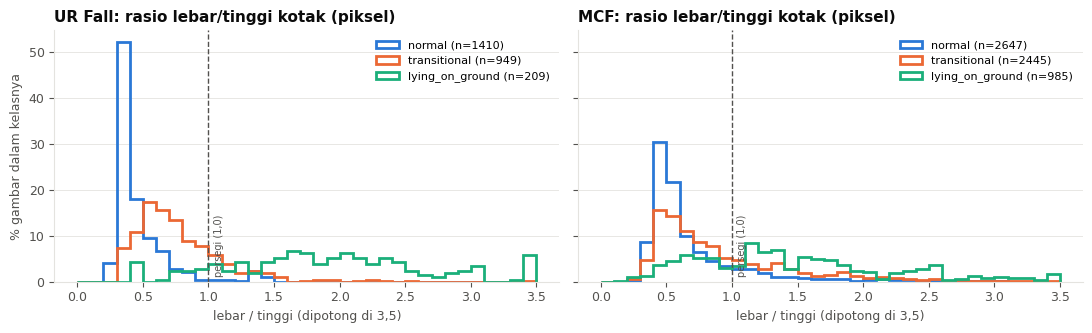

In [17]:
fm["ar_norm"], fm["ar_px"] = fm.w / fm.h, fm.bw / fm.bh
meta_g = fm.assign(sumber=fm.group)
t = meta_g.groupby(["kelas", "sumber"]).agg(n=("stem", "count"), w_norm=("w", "median"), h_norm=("h", "median"),
                                             ar_ternormalisasi=("ar_norm", "median"), ar_piksel=("ar_px", "median"),
                                             ar_piksel_gt1_pct=("ar_px", lambda s: pct((s > 1).mean())))
display(t.reindex(CLASS_ORDER, level=0).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
edges = np.linspace(0, 3.5, 36)
for ax, so in zip(axes, SOURCES):
    for k, nm in CLASS_NAMES.items():
        v = fm.loc[(fm.src == so) & (fm.cls == k), "ar_px"].clip(upper=3.5)
        ax.hist(v, bins=edges, weights=np.full(len(v), 100 / len(v)), histtype="step", lw=2,
                color=CLASS_COLOR[k], label=f"{nm} (n={len(v)})")
    ax.axvline(1, color=INK_MUTED, lw=1, ls="--")
    ax.text(1.04, 1, "persegi (1,0)", rotation=90, fontsize=7, color=INK_MUTED, va="bottom")
    ax.set_title(f"{SOURCE_LABEL[so]}: rasio lebar/tinggi kotak (piksel)")
    ax.set_xlabel("lebar / tinggi (dipotong di 3,5)")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("% gambar dalam kelasnya")
plt.tight_layout()
plt.show()

**Interpretasi.**
- Dalam piksel, kotak **lying lebih lebar daripada tinggi** di kedua sumber (median MCF 1,32; UR Fall 1,85).
  Angka audit lama untuk lying MCF (sekitar 0,9, "hampir persegi") adalah artefak koordinat ternormalisasi.
- Meski begitu, sebaran rasio **bertumpuk**, terutama di MCF yang direkam dari atas dengan lensa sudut lebar:
  30% kotak lying MCF justru lebih tinggi daripada lebar (rasio ≤ 1), sementara 32% kotak transitional MCF dan 15%
  kotak normal MCF lebih lebar daripada tinggi. Rasio kotak saja tidak cukup untuk memisahkan kelas; ini konsisten
  dengan hasil pendekatan rumus sudut + aspect ratio (EXP-009/010) yang terbatas.

## 7. Review label

Di dataset ini **tidak ada label yang digambar manusia**. Kelas berasal dari anotasi resmi dataset (CSV per frame UR Fall;
segmen waktu MCF yang disinkronkan ke 8 kamera), sedangkan kotak dibuat otomatis oleh detektor COCO. Karena itu review
label di sini mencakup tiga hal: (1) konsistensi label final terhadap sumbernya, (2) semantik kelas (apakah "lying"
benar-benar terbaring di lantai), dan (3) kualitas serta bias kotak otomatis.

### 7.1 Konsistensi label final terhadap sumber (baru)

Setiap label final dibandingkan dengan kelas yang **seharusnya** menurut `frames_meta.csv` + aturan Tahap 5
(`new_class` di `make_training_set.py`), dan ukuran kotaknya dibandingkan dengan yang tercatat di `frames_meta.csv`.

In [18]:
mts = load_script("make_training_set")
adl_normal, adl_drop = set(fin["adl_lying_normal"]), set(fin["adl_lying_drop"])
mrow = meta.set_index("stem").loc[fm.stem].reset_index()
expected = [mts.new_class(r, adl_normal, adl_drop, fin["keep_transitional"]) for r in mrow.to_dict("records")]
fm["cls_expected"] = expected
mismatch_cls = int((fm.cls != fm.cls_expected).sum())
mismatch_box = int(((fm.w - mrow.w.to_numpy()).abs().gt(1e-3) | (fm.h - mrow.h.to_numpy()).abs().gt(1e-3)).sum())
print(f"Kelas final berbeda dari aturan Tahap 5          : {mismatch_cls}")
print(f"Ukuran kotak final berbeda dari frames_meta.csv  : {mismatch_box}")
print("Perpindahan kelas processed_v2 -> final:")
display(pd.crosstab(mrow.cls.map(CLASS_NAMES).rename("kelas processed_v2"), fm.kelas.rename("kelas final"))
        .reindex(index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0))

Kelas final berbeda dari aturan Tahap 5          : 0
Ukuran kotak final berbeda dari frames_meta.csv  : 0
Perpindahan kelas processed_v2 -> final:


kelas final,normal,transitional,lying_on_ground
kelas processed_v2,,,
normal,3989,0,0
transitional,0,3394,0
lying_on_ground,68,0,1194


**Interpretasi.** Semua label final sesuai aturan Tahap 5, dan kotaknya tidak berubah dari `processed_v2`.
Satu-satunya perpindahan kelas adalah frame lying dari adl-10 dan adl-11 yang menjadi normal (sesuai keputusan
di §7.2). Tidak ada label yang "hilang arah" di tengah pipeline.

### 7.2 Semantik "lying" pada sequence ADL UR Fall (audit #2)

ADL adalah aktivitas harian tanpa jatuh, tetapi CSV UR Fall memberi label `lying` (*lying on the ground*) pada beberapa
frame ADL. Apakah itu orang yang terbaring di lantai?

,split,frame_lying,keputusan Tahap 5,bukti visual tercatat
video,,,,
adl-10,train,34,-> normal,ya (gambar kontak)
adl-11,train,34,-> normal,ya (gambar kontak)
adl-21,train,3,dibuang,tidak
adl-22,train,1,dibuang,tidak
adl-23,train,1,dibuang,tidak
adl-30,val,50,dibuang,ya (gambar kontak)
adl-32,val,4,dibuang,tidak
adl-33,val,11,dibuang,tidak
adl-34,val,12,dibuang,tidak


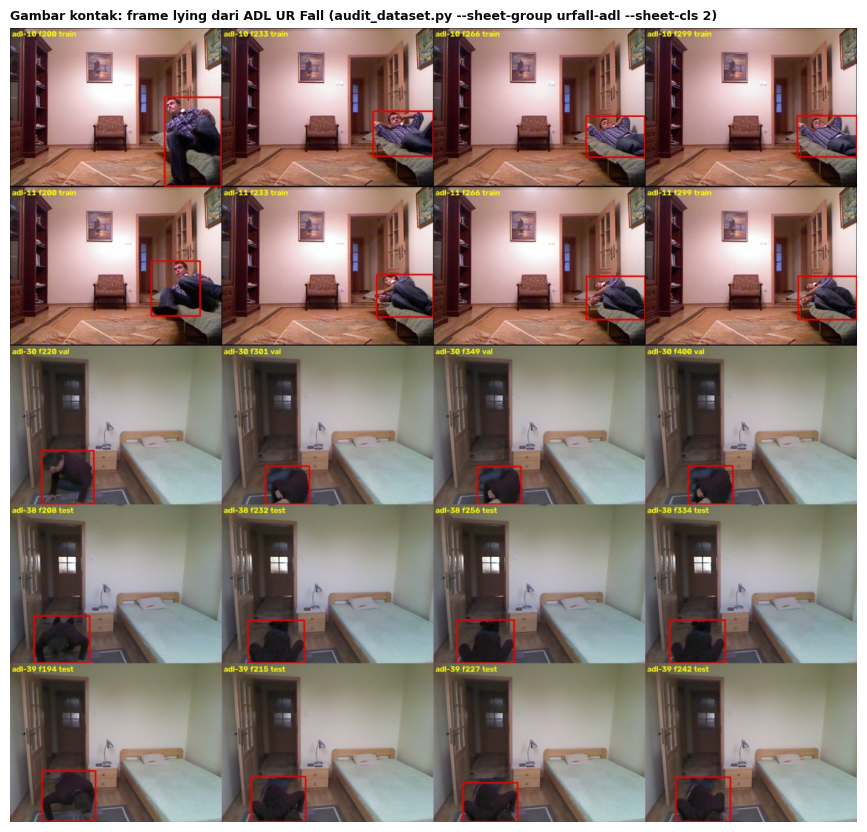

In [19]:
adl = meta[(meta.group == "urfall-adl") & (meta.cls == 2)].groupby("video").agg(
    split=("split", "first"), frame_lying=("stem", "count"))
adl["keputusan Tahap 5"] = ["-> normal" if v in adl_normal else ("dibuang" if v in adl_drop else "tetap lying")
                            for v in adl.index]
adl["bukti visual tercatat"] = ["ya (gambar kontak)" if v in {"adl-10", "adl-11", "adl-30", "adl-38", "adl-39"}
                                else "tidak" for v in adl.index]
display(adl)

sheet = D_V2 / "sheet_urfall-adl_c2.jpg"
if sheet.exists():
    img = cv2.cvtColor(cv2.imread(str(sheet)), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (1400, int(img.shape[0] * 1400 / img.shape[1])), interpolation=cv2.INTER_AREA)
    fig, ax = plt.subplots(figsize=(11, 11 * img.shape[0] / img.shape[1]))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title("Gambar kontak: frame lying dari ADL UR Fall (audit_dataset.py --sheet-group urfall-adl --sheet-cls 2)",
                 fontsize=9)
    plt.show()
else:
    print("gambar kontak tidak ditemukan:", rel(sheet))

**Pengamatan (pembacaan visual):**
- **adl-10 dan adl-11:** orang berbaring di sofa/kasur, bukan jatuh, sehingga wajar dijadikan **normal**. Ini konsisten
  dengan keputusan MCF kode 8 (sofa = normal).
- **adl-30, adl-38, adl-39:** orang tampak berlutut atau merangkak di lantai dekat tempat tidur. Label `lying` dari CSV
  tidak mencerminkan postur berbaring, jadi frame-nya **dibuang**.
- **Celah dokumentasi:** sepuluh sequence lain di daftar buang (masing-masing 1–12 frame) tidak punya bukti visual
  tercatat. Jumlah frame-nya kecil (total 51 dari 133 yang dibuang), tetapi alasannya sebaiknya dicatat.
- **Konsekuensi:** karena lying ADL di val/test ikut dibuang, model **tidak pernah diuji** pada "orang berbaring di
  kasur/sofa UR Fall" sebagai negatif; uji negatif semacam itu hanya ada dari MCF S23 (sofa).

### 7.3 Hard negative: MCF kode 8, berbaring di sofa = normal (gambar kontak, baru dibahas)

frame
split video       
test  s23       51
train s13        7
      s14       35

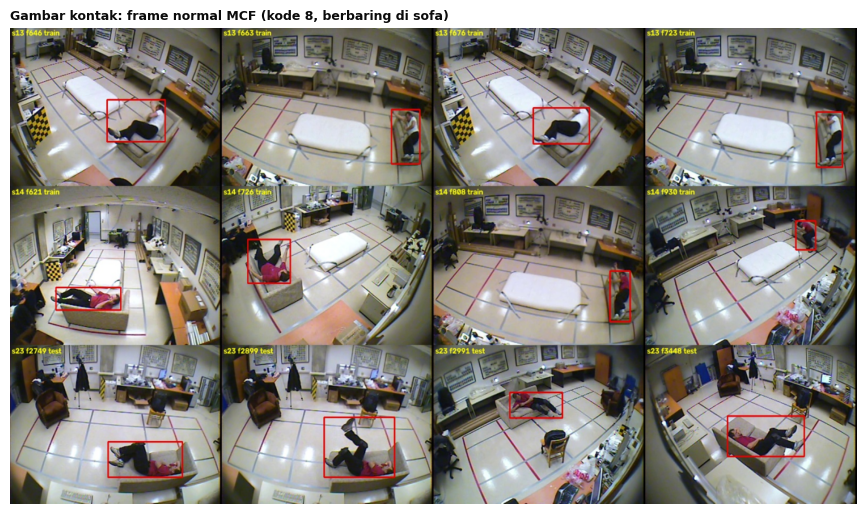

In [20]:
sofa = meta[(meta.group == "mcf") & (meta.code == 8)].groupby(["split", "video"]).size().rename("frame")
display(sofa.to_frame())
sheet = D_V2 / "sheet_mcf_c0.jpg"
if sheet.exists():
    img = cv2.cvtColor(cv2.imread(str(sheet)), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (1400, int(img.shape[0] * 1400 / img.shape[1])), interpolation=cv2.INTER_AREA)
    fig, ax = plt.subplots(figsize=(11, 11 * img.shape[0] / img.shape[1]))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title("Gambar kontak: frame normal MCF (kode 8, berbaring di sofa)", fontsize=9)
    plt.show()
else:
    print("gambar kontak tidak ditemukan:", rel(sheet))

**Pengamatan (pembacaan visual):**
- Kotak berada pada orang, dan posturnya **horizontal, mirip lying**; yang membedakan hanya alasnya (sofa vs lantai
  atau matras di lantai). Ini contoh *hard negative* paling sulit.
- Contoh sofa di **train hanya dari S13 dan S14** (42 frame), sedangkan **test S23** (51 frame) memakai sofa di posisi
  ruangan yang berbeda. Sedikitnya contoh sofa di train konsisten dengan alarm palsu yang terkonsentrasi di S23 pada
  eksperimen YOLO11-pose (84 dari 86 alarm palsu).
- Gambar MCF direkam dengan **lensa sudut lebar** (distorsi tong terlihat di tepi), sehingga bentuk tubuh di tepi
  gambar ikut terdistorsi.

### 7.4 Kualitas dan bias kotak otomatis (manifest)

In [21]:
drop = pd.DataFrame({"UR Fall": m1["no_person_by_class"], "MCF": mm["dropped_no_detection"]}).reindex(CLASS_ORDER)
kept = pd.DataFrame({"UR Fall": m1["totals"],
                     "MCF": {c: sum(v[0] for k, v in mm["retention_per_cam"].items() if k.endswith("/" + c))
                             for c in CLASS_ORDER}}).reindex(CLASS_ORDER)
print("Frame dibuang karena detektor tidak menemukan orang, dan persentasenya dari (dibuang + tersimpan):")
display(pd.concat({"dibuang": drop, "dibuang (%)": pct(drop / (drop + kept))}, axis=1))

ret = {}
for key, (kp, cd) in mm["retention_per_cam"].items():
    cam, cls = key.split("/")
    ret.setdefault(cls, {})[cam] = round(100 * kp / cd) if cd else np.nan
ret = pd.DataFrame(ret).T.reindex(CLASS_ORDER)
print("Retensi deteksi MCF per kamera (% kandidat yang tersimpan):")
display(ret)
print("Frame MCF yang kotaknya diganti oleh filter objek statis:", mm["box_changed_by_static_filter"])

Frame dibuang karena detektor tidak menemukan orang, dan persentasenya dari (dibuang + tersimpan):


dibuang       dibuang (%)      
                UR Fall   MCF     UR Fall   MCF
normal              241   740        15.2  21.8
transitional        406  1083        23.6  25.0
lying_on_ground     397  1023        49.2  50.9

Retensi deteksi MCF per kamera (% kandidat yang tersimpan):


,cam1,cam2,cam3,cam4,cam5,cam6,cam7,cam8
normal,74,76,80,80,84,77,72,83
transitional,74,82,78,66,76,63,79,82
lying_on_ground,53,74,29,29,69,45,56,37


Frame MCF yang kotaknya diganti oleh filter objek statis: {'normal': 54, 'transitional': 97, 'lying_on_ground': 31}


**Interpretasi.**
- Frame yang terbuang karena tanpa deteksi **paling banyak di kelas lying**: 51% kandidat lying MCF dan 49% lying
  UR Fall hilang, jauh di atas normal. Dataset karenanya condong ke lying yang *mudah* dideteksi detektor COCO.
- Di MCF, retensi lying **sangat timpang antar-kamera**: cam3 dan cam4 hanya 29%, cam8 37%, sedangkan cam2 74%.
  Sudut kamera tertentu nyaris tidak terwakili untuk lying, sehingga model kurang belajar dari sudut itu.
- Filter objek statis mengganti kotak pada 182 frame MCF; tanpa filter, kotak-kotak itu akan menunjuk benda.
- Kotak tidak pernah diperiksa satu per satu oleh manusia. Audit visual sampel dari pipeline pseudo-keypoint
  (notebook YOLO11-pose) menemukan sekitar 2 dari 12 frame lying MCF dengan kotak yang tidak tepat pada orang yang
  berbaring; angka ini masih pembacaan awal, belum audit resmi.

### 7.5 Posisi frame transitional di dalam segmennya (audit #4)

In [22]:
tr_pos = meta[(meta.cls == 1) & meta.seg_pos.notna()].copy()
tr_pos["bagian"] = pd.cut(tr_pos.seg_pos, [-0.001, 1 / 3, 2 / 3, 1.0], labels=["awal", "tengah", "akhir"])
display(pct(pd.crosstab(tr_pos.group, tr_pos.bagian, normalize="index")))

bagian,awal,tengah,akhir
group,,,
mcf,40.3,32.2,27.5
urfall-adl,35.3,29.8,34.9
urfall-fall,34.2,31.5,34.2


**Interpretasi.** Frame transitional tersebar hampir merata di awal, tengah, dan akhir segmennya. Tidak ada
bagian segmen yang terwakili berlebihan, sehingga subsampling transitional di Tahap 5 cukup dilakukan secara acak.
Catatan: label transitional di batas segmen paling rawan salah (batas anotasi dan selisih sinkronisasi kamera),
dan frame di sepertiga awal/akhir mencakup sekitar dua pertiga data.

## 8. Distribusi kelas dan sampel per kelas

### 8.1 Sebelum Tahap 5: `processed_v2` per sumber × split × kelas (audit #1)

In [23]:
GROUPS = ["urfall-fall", "urfall-adl", "mcf"]
IDX = pd.MultiIndex.from_product([GROUPS, SPLITS], names=["group", "split"])
print("Frame:")
display(meta.pivot_table(index=["group", "split"], columns="kelas", values="stem", aggfunc="count")
        .reindex(index=IDX, columns=CLASS_ORDER).fillna(0).astype(int))
print("Jumlah video/skenario yang memuat kelas tersebut:")
display(meta.pivot_table(index=["group", "split"], columns="kelas", values="video", aggfunc="nunique")
        .reindex(index=IDX, columns=CLASS_ORDER).fillna(0).astype(int))
share = meta.pivot_table(index="kelas", columns="group", values="stem", aggfunc="count", fill_value=0)
print("Porsi sumber di tiap kelas (%):")
display(pct(share.div(share.sum(axis=1), axis=0)).reindex(CLASS_ORDER))
trn = meta[meta.split == "train"].kelas.value_counts().reindex(CLASS_ORDER)
print("Train processed_v2 per kelas:", dict(trn), "->", dict(pct(trn / trn.sum())), "%")

Frame:


kelas              normal  transitional  lying_on_ground
group       split                                       
urfall-fall train     196           586              183
            val        19            96               14
            test       34           127               12
urfall-adl  train     820           157               73
            val       110           159               77
            test      163           188               51
mcf         train     718          1585              619
            val       449           515              114
            test     1480          1145              252

Jumlah video/skenario yang memuat kelas tersebut:


kelas              normal  transitional  lying_on_ground
group       split                                       
urfall-fall train      21            21               19
            val         4             4                3
            test        5             5                2
urfall-adl  train      28             5                5
            val         6             5                4
            test        6             6                6
mcf         train      14            14               14
            val         4             4                4
            test        6             5                4

Porsi sumber di tiap kelas (%):


group,mcf,urfall-adl,urfall-fall
kelas,,,
normal,66.4,27.4,6.2
transitional,71.2,11.1,17.7
lying_on_ground,70.6,14.4,15.0


Train processed_v2 per kelas: {'normal': np.int64(1734), 'transitional': np.int64(2328), 'lying_on_ground': np.int64(875)} -> {'normal': np.float64(35.1), 'transitional': np.float64(47.2), 'lying_on_ground': np.float64(17.7)} %


**Interpretasi.** Sebelum Tahap 5, **transitional adalah kelas terbesar di train** (2.328 dari 4.937 frame, 47%)
karena stride transitional dibuat rapat. Ultralytics tidak menyediakan bobot per kelas, sehingga ketimpangan ini
diatasi di level data dengan subsampling 50% transitional di train (Tahap 5). Ketiga kelas terutama berasal dari MCF
(sekitar 66–71%), jadi tidak ada kelas yang hanya hidup di satu sumber. Ini mengurangi risiko model belajar
"sumber = kelas".

### 8.2 Komposisi normal MCF per kode aktivitas — hard negative (audit #3)

In [24]:
mn = meta[(meta.group == "mcf") & (meta.cls == 0)].dropna(subset=["code"]).assign(kode=lambda d: d.code.astype(int))
t = mn.pivot_table(index="kode", columns="split", values="stem", aggfunc="count", fill_value=0).reindex(columns=list(SPLITS))
t.insert(0, "aktivitas", [etm.CODE_NAMES[k] for k in t.index])
display(t)

split,aktivitas,train,val,test
kode,,,,
1,walking_standing_up,524,124,1018
4,crouching,0,18,75
5,moving_down,55,112,117
6,moving_up,82,108,162
7,sitting,15,87,57
8,lying_on_sofa,42,0,51


**Interpretasi.** Normal MCF didominasi berjalan/berdiri (kode 1). Negatif yang mirip jatuh justru tipis di train:
jongkok (kode 4) **0 frame**, duduk (kode 7) 15 frame, sofa (kode 8) 42 frame. Model belajar sangat sedikit tentang
"postur rendah yang bukan jatuh", sedangkan test memuat 75 frame jongkok dan 51 frame sofa.

### 8.3 Dataset final (`processed_final`): kelas per split dan sumber

Frame per dataset x split x kelas:


kelas                       normal  transitional  lying_on_ground
dataset              split                                       
UR Fall (fall + ADL) train    1084           379              183
                     val       129           255               14
                     test      197           315               12
MCF                  train     718           785              619
                     val       449           515              114
                     test     1480          1145              252

Komposisi kelas per split (%), total frame, dan porsi MCF:

kelas,normal,transitional,lying_on_ground,total frame,porsi MCF (%)
split,,,,,
train,47.8,30.9,21.3,3768,56.3
val,39.2,52.2,8.7,1476,73.0
test,49.3,42.9,7.8,3401,84.6


Hitungan dari file label = manifest: ya


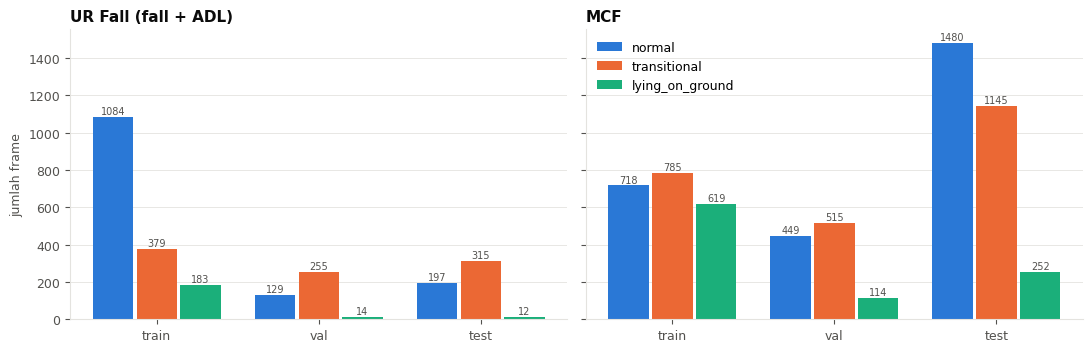

In [25]:
rows = [dict(zip(("sumber", "split", "kelas"), k.split("/")), frame=n) for k, n in fin["counts"].items()]
fdf = pd.DataFrame(rows)
fdf["dataset"] = np.where(fdf.sumber == "mcf", "MCF", "UR Fall (fall + ADL)")
DS = ["UR Fall (fall + ADL)", "MCF"]
agg = (fdf.groupby(["dataset", "split", "kelas"]).frame.sum().unstack("kelas")
       .reindex(index=pd.MultiIndex.from_product([DS, SPLITS], names=["dataset", "split"]), columns=CLASS_ORDER)
       .fillna(0).astype(int))
print("Frame per dataset x split x kelas:")
display(agg)

tot = agg.groupby("split").sum().reindex(list(SPLITS))
comp = pct(tot.div(tot.sum(axis=1), axis=0))
comp["total frame"] = tot.sum(axis=1)
comp["porsi MCF (%)"] = pct(agg.loc["MCF"].sum(axis=1) / tot.sum(axis=1))
print("Komposisi kelas per split (%), total frame, dan porsi MCF:")
display(comp)
check = fm.groupby(["split", "kelas"]).size().unstack().reindex(index=list(SPLITS), columns=CLASS_ORDER)
assert (check.values == tot.values).all(), "hitungan file berbeda dari manifest"
print("Hitungan dari file label = manifest: ya")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, ds in zip(axes, DS):
    x = np.arange(len(SPLITS))
    for i, (k, nm) in enumerate(CLASS_NAMES.items()):
        vals = agg.loc[ds, nm].reindex(list(SPLITS)).values
        bars = ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=CLASS_COLOR[k], label=nm)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 15, f"{v}", ha="center", fontsize=7, color=INK_MUTED)
    ax.set_xticks(x)
    ax.set_xticklabels(SPLITS)
    ax.set_title(ds)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("jumlah frame")
axes[1].legend(loc="upper left", frameon=False, ncol=1)
plt.tight_layout()
plt.show()

**Interpretasi.**
- Total **8.645 frame**: normal 4.057, transitional 3.394, lying 1.194. Lying adalah kelas terkecil di semua split
  (train 21%, val 9%, test 8%).
- Komposisi val/test **tidak mencerminkan frekuensi nyata** di lapangan: transitional di-oversample oleh stride
  rapat, dan test didominasi MCF (85%).
- UR Fall hanya menyumbang **12 frame lying di test** (dan 14 di val). Pengujian lying hampir seluruhnya bergantung
  pada MCF.

### 8.4 Kejadian lying per split (baru)

Frame berurutan dari satu kejadian tidak independen. Untuk metrik lying, unit yang lebih jujur adalah **kejadian**:
satu video UR Fall, atau satu skenario MCF (semua kameranya merekam kejadian yang sama).

In [26]:
ly = fm[fm.cls == 2]
ev = ly.groupby(["split", "group", "video"]).agg(frame=("stem", "count"), kamera=("cam", "nunique")).reset_index()
ev.loc[ev.group != "mcf", "kamera"] = 1
summary = ev.groupby("split").agg(kejadian=("video", "count"), frame=("frame", "sum"),
                                  frame_per_kejadian_median=("frame", "median")).reindex(list(SPLITS))
summary["kejadian MCF"] = ev[ev.group == "mcf"].groupby("split").size().reindex(list(SPLITS)).fillna(0).astype(int)
summary["kejadian UR Fall"] = summary.kejadian - summary["kejadian MCF"]
display(summary)
print("Rincian kejadian lying di test:")
display(ev[ev.split == "test"].drop(columns="split").set_index(["group", "video"]))

default ={s: mm["counts"][f"{s}/lying_on_ground"]["scenarios"] for s in SPLITS}
actual_ly = ev[ev.group == "mcf"].groupby("split").video.apply(lambda v: sorted(int(x[1:]) for x in v)).to_dict()
print("Skenario MCF yang memuat lying — split default prepare_mcf.py vs yang berlaku (--mcf-split):")
display(pd.DataFrame({"default (1-16/17-20/21-24)": {s: f"{len(default[s])}: {sorted(default[s])}" for s in SPLITS},
                      "berlaku (1-14/15-18/19-24)": {s: f"{len(actual_ly.get(s, []))}: {actual_ly.get(s, [])}"
                                                    for s in SPLITS}}))

,kejadian,frame,frame_per_kejadian_median,kejadian MCF,kejadian UR Fall
split,,,,,
train,33,802,18.0,14,19
val,7,128,13.0,4,3
test,6,264,54.5,4,2


Rincian kejadian lying di test:


frame  kamera
group       video                 
mcf         s19         64       7
            s20         54       8
            s21         79       8
            s22         55       8
urfall-fall fall-26      7       1
            fall-30      5       1

Skenario MCF yang memuat lying — split default prepare_mcf.py vs yang berlaku (--mcf-split):


,default (1-16/17-20/21-24),berlaku (1-14/15-18/19-24)
train,"16: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13...","14: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13..."
val,"4: [17, 18, 19, 20]","4: [15, 16, 17, 18]"
test,"2: [21, 22]","4: [19, 20, 21, 22]"


**Interpretasi.**
- Lying di dataset final berasal dari **33 kejadian di train, 7 di val, dan hanya 6 di test** (4 skenario MCF +
  2 video UR Fall). 264 frame lying test hanya mewakili 6 kejadian, jadi interval kepercayaan metrik lying per
  kejadian akan **sangat lebar**. Ini batas utama untuk menyimpulkan apakah satu model lebih baik dari yang lain.
- 252 dari 264 frame lying test berasal dari 4 skenario MCF; dua video UR Fall hanya menyumbang 7 dan 5 frame.
  Pada S19, lying hanya tersimpan dari 7 dari 8 kamera.
- Pemindahan skenario MCF (`--mcf-split`) menggandakan kejadian lying MCF di test dari 2 menjadi 4. Tanpa itu, test
  hanya punya 4 kejadian lying.
- **Alas lying MCF berimpit dengan split** (pemeriksaan visual manual, 2026-10-30): pada S01–S14 orang berbaring di
  atas **matras**, sedangkan S15–S24 memuat bagian orang berbaring **langsung di lantai** tanpa matras. Dengan split
  yang berlaku (1-14/15-18/19-24), seluruh lying MCF di train beralas matras, dan lying MCF di lantai hanya ada di val
  dan test. Temuan ini berbeda dari dokumentasi penulis dataset (*technical report* hal. 5 menyebut matras dipakai
  untuk melindungi aktor); yang dipegang adalah hasil pemeriksaan visual.

### 8.5 Contoh frame per sumber × kelas (train, dengan kotak anotasi)

Satu contoh per sumber × kelas, diambil dari tengah daftar berurutan agar tidak selalu frame pertama.

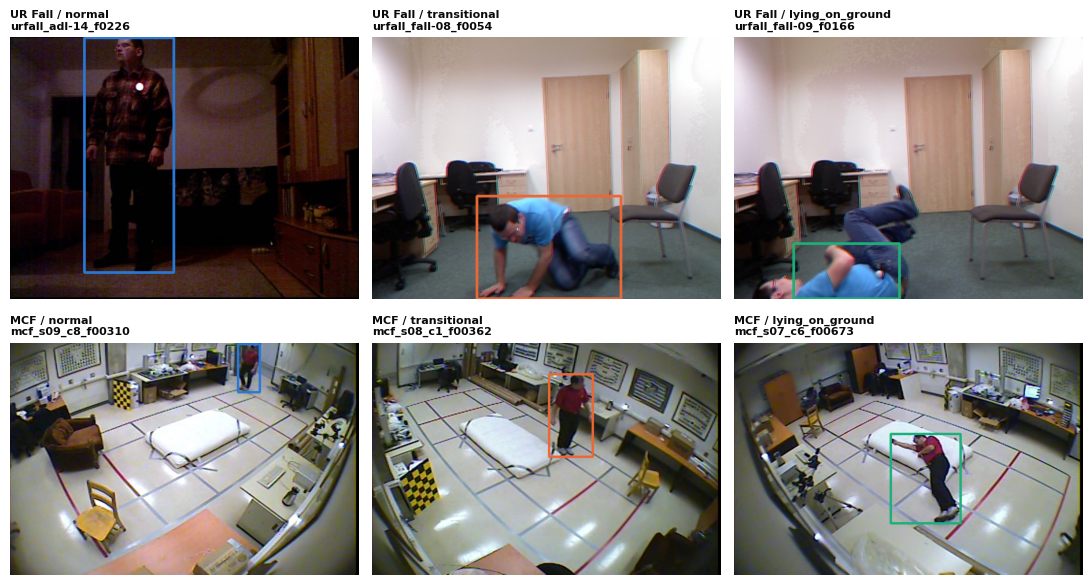

In [27]:
def hex_to_bgr(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) for i in (4, 2, 0))


fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for r, so in enumerate(SOURCES):
    for c in (0, 1, 2):
        ax = axes[r][c]
        ax.axis("off")
        hits = fm[(fm.split == "train") & (fm.src == so) & (fm.cls == c)].sort_values("stem")
        if hits.empty:
            continue
        row = hits.iloc[len(hits) // 2]
        img = cv2.imread(str(D_FINAL / "images" / "train" / f"{row.stem}.jpg"))
        H, W = img.shape[:2]
        cv2.rectangle(img, (int((row.xc - row.w / 2) * W), int((row.yc - row.h / 2) * H)),
                      (int((row.xc + row.w / 2) * W), int((row.yc + row.h / 2) * H)), hex_to_bgr(CLASS_COLOR[c]), 4)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{SOURCE_LABEL[so]} / {CLASS_NAMES[c]}\n{row.stem}", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

**Pengamatan (pembacaan visual, satu contoh per sel, bukan statistik):**
- **UR Fall / lying (`urfall_fall-09_f0166`)**: kotak hanya mencakup badan dan kepala; kaki yang terangkat berada
  di luar kotak. Contoh kotak otomatis yang tidak lengkap pada pose tidak lazim.
- **MCF / transitional (`mcf_s08_c1_f00362`)**: orang masih tampak berdiri tegak padahal berlabel transitional.
  Contoh label di batas segmen (atau sinkronisasi kamera non-acuan) yang meleset beberapa frame (§7.5).
- **MCF / lying (`mcf_s07_c6_f00673`)**: orang terbaring di atas **matras** di lantai. Alasnya berbeda antar skenario:
  matras pada S01–S14, lantai langsung pada S15–S24 (§8.4).

## 9. Durasi lying per video (audit #7)

Aturan alarm proyek: orang terbaring **≥ 10 detik**. Apakah dataset bisa menguji aturan itu?

In [28]:
pm = load_script("prepare_mcf")
ann = pm.load_annotations(MCF_DIR / "annotations.csv", pm.load_label_map(MCF_DIR / "label_map.yaml"))
FPS = 30.0   # ASUMSI di audit_dataset.py (belum diverifikasi dari metadata video)
dur = {"mcf": [], "urfall-fall": [], "urfall-adl": []}
for sc, d in ann.items():
    tot_ = sum(en - st + 1 for st, en, code_ in d["segments"] if code_ == 3)
    if tot_:
        dur["mcf"].append(tot_)
lyv = meta[meta.cls == 2].groupby(["group", "video"]).frame.agg(lambda s: s.max() - s.min() + 1)
for g in ("urfall-fall", "urfall-adl"):
    dur[g] = lyv[g].tolist() if g in lyv.index.get_level_values(0) else []
rows = []
for g, v in dur.items():
    if v:
        v = sorted(v)
        rows.append({"sumber": g, "video": len(v), "min (detik)": v[0] / FPS, "median (detik)": v[len(v) // 2] / FPS,
                     "maks (detik)": v[-1] / FPS, "video >= 10 detik": f"{sum(x / FPS >= 10 for x in v)}/{len(v)}"})
display(pd.DataFrame(rows).round(1))
print(f"(Asumsi {FPS:g} FPS; MCF dihitung dari anotasi kode 3 di kamera acuan, "
      "UR Fall dari rentang frame lying di processed_v2.)")

,sumber,video,min (detik),median (detik),maks (detik),video >= 10 detik
0,mcf,22,1.0,4.1,6.9,0/22
1,urfall-fall,24,0.0,0.6,2.0,0/24
2,urfall-adl,15,0.0,1.7,6.0,0/15


(Asumsi 30 FPS; MCF dihitung dari anotasi kode 3 di kamera acuan, UR Fall dari rentang frame lying di processed_v2.)


**Interpretasi.** Dengan asumsi 30 FPS, **tidak ada** video dengan lying ≥ 10 detik (MCF maksimal sekitar
7 detik). Aturan alarm 10 detik **tidak dapat diuji** dengan dataset ini; evaluasi hanya bisa di level frame atau
kejadian pendek. Untuk UR Fall, angkanya adalah batas bawah karena dihitung dari frame yang lolos stride dan deteksi.
Asumsi 30 FPS sendiri belum diverifikasi dari metadata video.

## 10. Ringkasan temuan

### 10.1 Jawaban per pertanyaan

| Pertanyaan | Temuan | Sumber angka | § |
|---|---|---|---|
| Jumlah gambar dan kelas | **8.645 gambar, 3 kelas** (normal 4.057, transitional 3.394, lying 1.194). Train 3.768, val 1.476, test 3.401. Setiap gambar punya tepat satu label. | manifest + dihitung | 3, 8.3 |
| File rusak | **0** gambar hilang, salah header, terpotong, atau gagal di-decode. | dihitung | 4.1 |
| Duplikat persis | **0** grup file identik (MD5). | dihitung | 4.2 |
| Format label | Semua valid: 1 objek per gambar, 5 kolom, kelas 0–2, koordinat 0–1, tidak keluar tepi. | dihitung | 4.3 |
| Kebocoran antar-split | **0** video/skenario muncul di lebih dari satu split. | dihitung | 5.1 |
| Near-duplicate (frame utuh) | Tidak bermakna sebagai duplikat: hash didominasi latar belakang. Train **dan** test MCF berbagi ruangan dan kamera yang sama (100% pasangan dekat lintas split berasal dari kamera yang sama). | dihitung | 5.3 |
| Near-duplicate (potongan orang) | Lintas split hanya 0,1–3,8% (d ≤ 6). Di dalam train, 3.768 gambar ≈ 2.788 kelompok pose (d ≤ 6) dan ≈ 2.038 (d ≤ 10). | dihitung | 5.4 |
| Resolusi | Hanya dua: UR Fall **640×480** (2.568 gambar), MCF **720×480** (6.077 gambar). Tidak ada gambar beresolusi rendah. | dihitung | 6.1 |
| Orang terlalu kecil | Hanya 1 kotak small (COCO, < 32² px) pada resolusi asli; 7 setelah diskalakan ke 640. Orang MCF jauh lebih kecil (median tinggi normal 147 px vs 264 px UR Fall). Ini terutama efek seleksi: frame tanpa deteksi sudah dibuang. | dihitung + manifest | 6.2, 7.4 |
| Bentuk kotak | Dalam piksel, lying lebih lebar daripada tinggi (median MCF 1,32; UR Fall 1,85), tetapi sebarannya bertumpuk dengan kelas lain. Angka audit lama (rasio ternormalisasi) keliru untuk menilai bentuk. | dihitung | 6.3 |
| Konsistensi label | Label final 100% sesuai aturan Tahap 5; kotak tidak berubah sejak `processed_v2`. | dihitung | 7.1 |
| Semantik lying ADL | adl-10/11 berbaring di sofa → normal; adl-30/38/39 berlutut/merangkak → dibuang. 10 sequence lain (51 frame) dibuang tanpa bukti visual tercatat. | pembacaan visual + dihitung | 7.2 |
| Bias kotak otomatis | Sekitar **50% kandidat lying hilang** karena detektor tidak menemukan orang (UR Fall 49%, MCF 51%), jauh di atas normal (15–22%). Retensi lying MCF per kamera timpang: cam3/cam4 29%, cam2 74%. | manifest | 7.4 |
| Distribusi kelas | Lying kelas terkecil di semua split (train 21%, val 9%, test 8%). Test 85% MCF. | manifest + dihitung | 8.3 |
| Kejadian lying | **33 kejadian di train, 7 di val, 6 di test.** 252 dari 264 frame lying test dari 4 skenario MCF. | dihitung | 8.4 |
| Alas lying MCF | S01–S14 (train) beralas **matras**; S15–S24 (val, test) memuat lying **langsung di lantai**. Alas berimpit dengan split. | pemeriksaan visual manual | 8.4 |
| Hard negative | Jongkok 0 frame dan sofa 42 frame di train; di test 75 dan 51 frame. | dihitung | 8.2, 7.3 |
| Durasi lying | Tidak ada video dengan lying ≥ 10 detik (asumsi 30 FPS); aturan alarm 10 detik tidak bisa diuji. | dihitung | 9 |

### 10.2 Yang paling berpengaruh pada pemodelan (fakta, bukan usulan)

1. **Unit statistik lying sangat kecil.** Test hanya punya 6 kejadian lying. Selisih performa antar-model akan sulit
   dibuktikan, berapa pun jumlah frame-nya.
2. **Sampel efektif lebih kecil dari jumlah gambar.** Pose di dalam train cukup berulang (≈ 2.800 kelompok dari 3.768
   gambar pada d ≤ 6), dan satu momen MCF muncul dari banyak kamera. Ini relevan untuk menilai risiko overfit model
   yang lebih besar.
3. **Test tidak menguji ruangan baru.** Train dan test MCF berbagi ruangan dan kamera; generalisasi ke lingkungan panti
   jompo yang berbeda belum teruji oleh split ini.
4. **Lying yang sulit kurang terwakili.** Sekitar separuh kandidat lying terbuang karena detektor COCO gagal, dan sudut
   kamera tertentu (cam3, cam4, cam8) nyaris hilang untuk lying.
5. **Hard negative tipis di train** (sofa, jongkok, duduk), sedangkan test memuatnya. Konsisten dengan alarm palsu yang
   terkonsentrasi di S23 (sofa) pada eksperimen YOLO11-pose.
6. **Kualitas file bukan masalah.** Tidak ada file rusak, duplikat persis, label cacat, atau resolusi rendah.
7. **Alas lying MCF berbeda antara train dan val/test.** Dari MCF, model hanya melihat lying di atas matras saat
   training, tetapi dievaluasi pada lying di lantai. Metrik lying di val/test karenanya ikut mengukur pergeseran
   domain ini; besarnya pengaruh belum diukur.

### 10.3 Celah yang belum tertutup

- Kotak otomatis belum pernah diaudit manual secara sistematis (baru pembacaan sampel).